### Question: 

Does a filter that works well for one type of noise also work well for another?

    Imagine robot is moving and rotating. Its IMU measures angular velocity.

    I will create two noisy measurements.

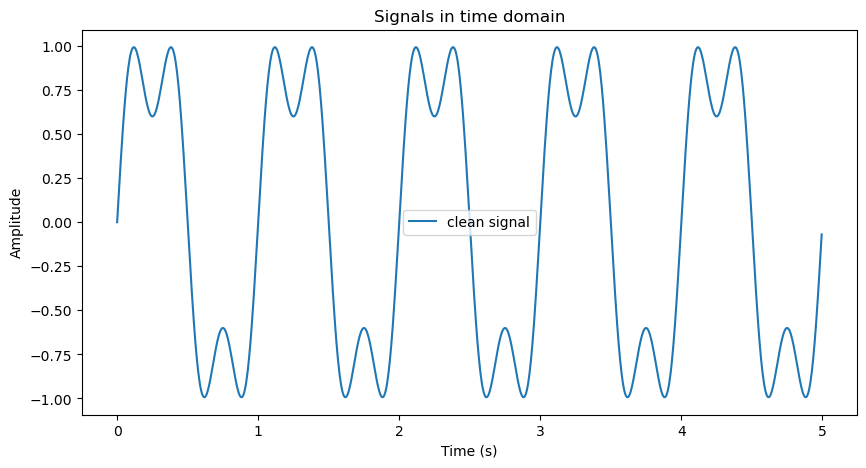

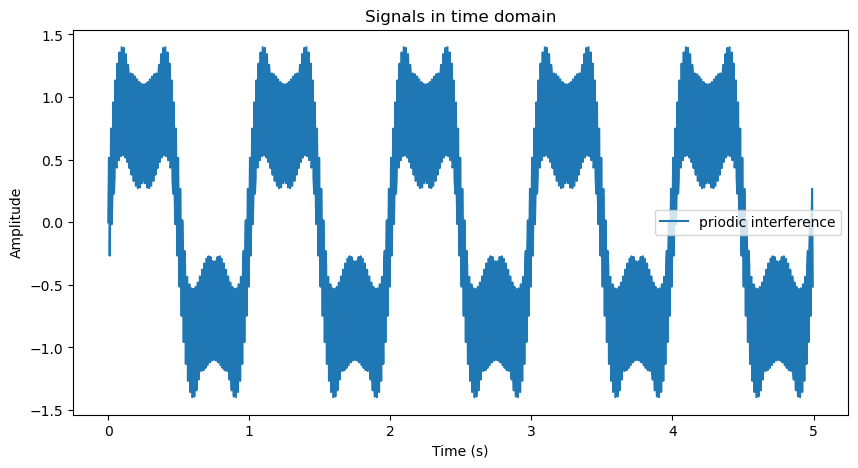

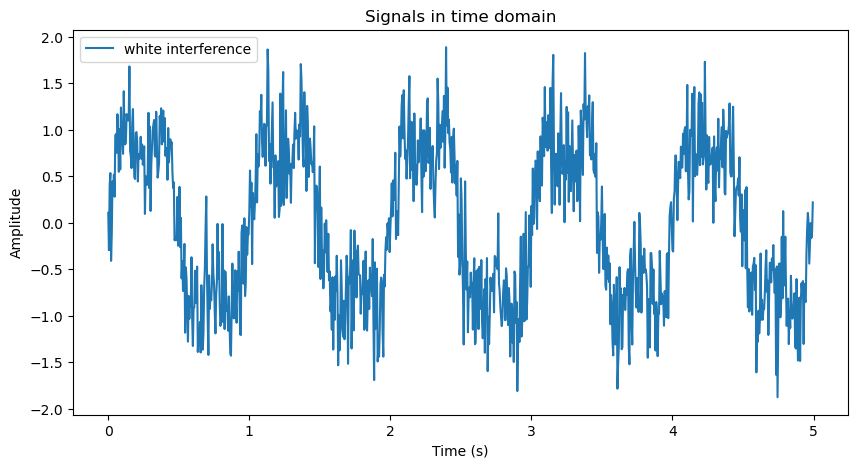

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import freqz, lfilter

fs = 200
duration = 5
N = fs * duration
t = np.arange(N) / fs

# True angular velocity
clean = ( np.sin(2*np.pi*1*t) + 0.4*np.sin(2*np.pi*3*t))

# Noise type A: periodic interference
noise_periodic = 0.5*np.sin(2*np.pi*65*t)

# Noise type B: random white noise
rng = np.random.default_rng(42)
noise_white = rng.normal(0, 0.35, N)

# Two noisy measurements
x_periodic = clean + noise_periodic
x_white = clean + noise_white

plt.figure(figsize=(10, 5))
plt.plot(t, clean, label="clean signal")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Signals in time domain")
plt.legend()
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(t, x_periodic, label="priodic interference")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Signals in time domain")
plt.legend()
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(t, x_white, label="white interference")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Signals in time domain")
plt.legend()
plt.show()

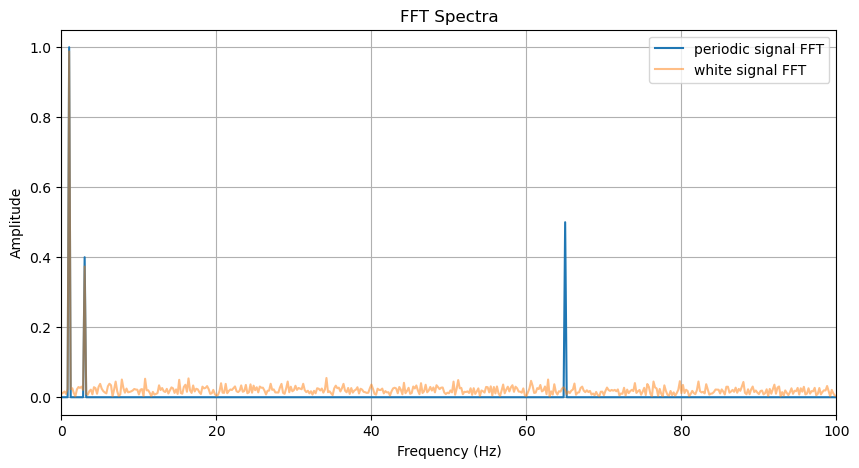

In [10]:
freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_periodic = (np.abs(np.fft.rfft(x_periodic)) / N)
amplitude_periodic[1:-1] *= 2
amplitude_white = (np.abs(np.fft.rfft(x_white)) / N)
amplitude_white[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_periodic, label="periodic signal FFT")
plt.plot(freq_fft, amplitude_white, label="white signal FFT", alpha= 0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("FFT Spectra")
plt.legend()
plt.xlim(0, 100)
plt.grid(True)
plt.show()

Now I am going to apply the same filters from previous practice two both signals and see whether the filters perform differently depending on noise type!

In [12]:
#FIR filter
b_fir = np.ones(7) / 7

#First-order IIR 
alpha = 0.7
b_iir = np.array([1-alpha])
a_iir = np.array([1, -alpha])

fir_periodic = lfilter(b_fir, [1], x_periodic)
iir_periodic = lfilter(b_iir, a_iir, x_periodic)
fir_white = lfilter(b_fir, [1], x_white)
iir_white = lfilter(b_iir, a_iir, x_white)

def rmse_calculator(filtered_out, clean_signal):
    rmse = np.sqrt(np.mean((filtered_out - clean_signal) ** 2))
    return rmse
    
mask = (t >= 0.5) & (t<= 1.5)
print("periodic interference :")
print("FIR RMSE = ", rmse_calculator(fir_periodic[mask], clean[mask]))
print("IIR RMSE = ", rmse_calculator(iir_periodic[mask], clean[mask]))
print("------------")
print("white noise")
print("FIR RMSE = ", rmse_calculator(fir_white[mask], clean[mask]))
print("IIR RMSE = ", rmse_calculator(iir_white[mask], clean[mask]))
    

periodic interference :
FIR RMSE =  0.11335355513375739
IIR RMSE =  0.10823268268593951
------------
white noise
FIR RMSE =  0.14068270630480037
IIR RMSE =  0.14977591233705911


From previous exercise we understood that FIR suppresses the 65 Hz interference more strongly, But now we see that the IIr have a slower RMSE!

This is because RMSE measures the overall difference between the filtered signal and the clean signal, not just the remaining noise.

Our FIR filter has a constant group delay of 15 ms, whereas the IIR has a smaller group delay at the useful low frequencies.

Even though the FIR removes more 65 Hz noise, its larger delay increases the difference from the clean signal at the same time points.

But, for white noise, FIR fits better.

Important Notice:

    1- A filter that removes more high-frequency noise does not necessarily have the lowest time-aligned RMSE
    
    2- Filtering delay matters when comparing sensor measurements against the true motion.
    

#### Conclusion

In the periodic interference experiment, the FIR filter attenuates the unwanted frequency more strongly, but the IIR filter achieves a slightly lower RMSE. This shows a trade-off between noise reduction and the changes introduced to the useful signal, including delay. If minimizing RMSE is our main priority, we may prefer the IIR filter. However, considering all the original design requirements, the FIR filter remains the better choice.